In [ ]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression, Lasso, Ridge
from sklearn.metrics import mean_squared_error, mean_absolute_error

In [ ]:
df = pd.read_csv('/content/California_Houses.csv')

In [ ]:
df.head()

,Median_House_Value,Median_Income,Median_Age,Tot_Rooms,Tot_Bedrooms,Population,Households,Latitude,Longitude,Distance_to_coast,Distance_to_LA,Distance_to_SanDiego,Distance_to_SanJose,Distance_to_SanFrancisco
0,452600.0,8.3252,41,880,129,322,126,37.88,-122.23,9263.040773,556529.158342,735501.806984,67432.517001,21250.213767
1,358500.0,8.3014,21,7099,1106,2401,1138,37.86,-122.22,10225.733072,554279.850069,733236.884360,65049.908574,20880.600400
2,352100.0,7.2574,52,1467,190,496,177,37.85,-122.24,8259.085109,554610.717069,733525.682937,64867.289833,18811.487450
3,341300.0,5.6431,52,1274,235,558,219,37.85,-122.25,7768.086571,555194.266086,734095.290744,65287.138412,18031.047568
4,342200.0,3.8462,52,1627,280,565,259,37.85,-122.25,7768.086571,555194.266086,734095.290744,65287.138412,18031.047568


In [ ]:
df.tail()

,Median_House_Value,Median_Income,Median_Age,Tot_Rooms,Tot_Bedrooms,Population,Households,Latitude,Longitude,Distance_to_coast,Distance_to_LA,Distance_to_SanDiego,Distance_to_SanJose,Distance_to_SanFrancisco
20635,78100.0,1.5603,25,1665,374,845,330,39.48,-121.09,162031.481121,654530.186299,830631.543047,248510.058162,222619.890417
20636,77100.0,2.5568,18,697,150,356,114,39.49,-121.21,160445.433537,659747.068444,836245.915229,246849.888948,218314.424634
20637,92300.0,1.7000,17,2254,485,1007,433,39.43,-121.22,153754.341182,654042.214020,830699.573163,240172.220489,212097.936232
20638,84700.0,1.8672,18,1860,409,741,349,39.43,-121.32,152005.022239,657698.007703,834672.461887,238193.865909,207923.199166
20639,89400.0,2.3886,16,2785,616,1387,530,39.37,-121.24,146866.196892,648723.337126,825569.179028,233282.769063,205473.376575


In [ ]:
df.shape

(20640, 14)

In [ ]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 20640 entries, 0 to 20639
Data columns (total 14 columns):
 #   Column                    Non-Null Count  Dtype  
---  ------                    --------------  -----  
 0   Median_House_Value        20640 non-null  float64
 1   Median_Income             20640 non-null  float64
 2   Median_Age                20640 non-null  int64  
 3   Tot_Rooms                 20640 non-null  int64  
 4   Tot_Bedrooms              20640 non-null  int64  
 5   Population                20640 non-null  int64  
 6   Households                20640 non-null  int64  
 7   Latitude                  20640 non-null  float64
 8   Longitude                 20640 non-null  float64
 9   Distance_to_coast         20640 non-null  float64
 10  Distance_to_LA            20640 non-null  float64
 11  Distance_to_SanDiego      20640 non-null  float64
 12  Distance_to_SanJose       20640 non-null  float64
 13  Distance_to_SanFrancisco  20640 non-null  float64
dtypes: flo

In [ ]:
df.describe()

,Median_House_Value,Median_Income,Median_Age,Tot_Rooms,Tot_Bedrooms,Population,Households,Latitude,Longitude,Distance_to_coast,Distance_to_LA,Distance_to_SanDiego,Distance_to_SanJose,Distance_to_SanFrancisco
count,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,20640.000000,2.064000e+04,2.064000e+04,20640.000000,20640.000000
mean,206855.816909,3.870671,28.639486,2635.763081,537.898014,1425.476744,499.539680,35.631861,-119.569704,40509.264883,2.694220e+05,3.981649e+05,349187.551219,386688.422291
std,115395.615874,1.899822,12.585558,2181.615252,421.247906,1132.462122,382.329753,2.135952,2.003532,49140.039160,2.477324e+05,2.894006e+05,217149.875026,250122.192316
min,14999.000000,0.499900,1.000000,2.000000,1.000000,3.000000,1.000000,32.540000,-124.350000,120.676447,4.205891e+02,4.849180e+02,569.448118,456.141313
25%,119600.000000,2.563400,18.000000,1447.750000,295.000000,787.000000,280.000000,33.930000,-121.800000,9079.756762,3.211125e+04,1.594264e+05,113119.928682,117395.477505
50%,179700.000000,3.534800,29.000000,2127.000000,435.000000,1166.000000,409.000000,34.260000,-118.490000,20522.019101,1.736675e+05,2.147398e+05,459758.877000,526546.661701
75%,264725.000000,4.743250,37.000000,3148.000000,647.000000,1725.000000,605.000000,37.710000,-118.010000,49830.414479,5.271562e+05,7.057954e+05,516946.490963,584552.007907
max,500001.000000,15.000100,52.000000,39320.000000,6445.000000,35682.000000,6082.000000,41.950000,-114.310000,333804.686371,1.018260e+06,1.196919e+06,836762.678210,903627.663298


In [ ]:
df.isnull().sum()

,0
Median_House_Value,0
Median_Income,0
Median_Age,0
Tot_Rooms,0
Tot_Bedrooms,0
Population,0
Households,0
Latitude,0
Longitude,0
Distance_to_coast,0


In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df= df.drop(['Latitude','Longitude'], axis=1)

In [ ]:
cat_columns=df.select_dtypes(include='object').columns
cat_columns

Index([], dtype='object')

In [ ]:
num_columns=df.select_dtypes(exclude='object').columns
num_columns

Index(['Median_House_Value', 'Median_Income', 'Median_Age', 'Tot_Rooms',
       'Tot_Bedrooms', 'Population', 'Households', 'Distance_to_coast',
       'Distance_to_LA', 'Distance_to_SanDiego', 'Distance_to_SanJose',
       'Distance_to_SanFrancisco'],
      dtype='object')

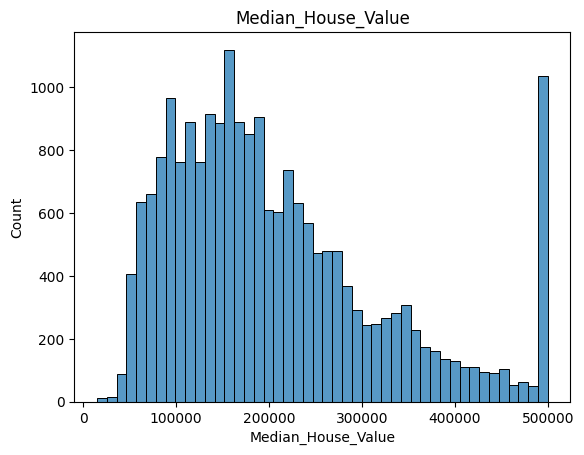

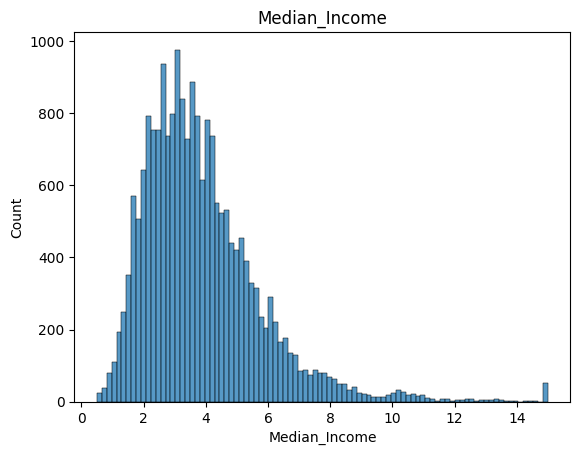

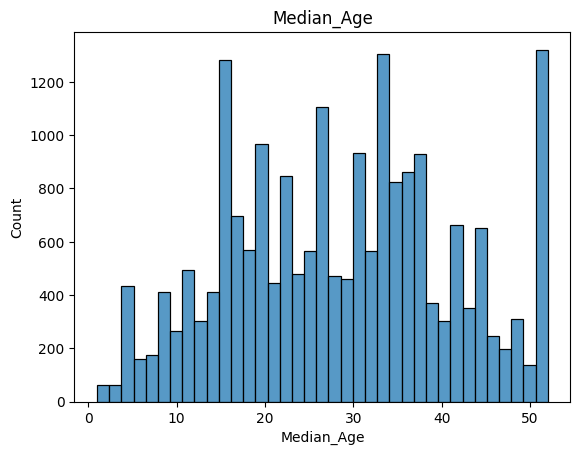

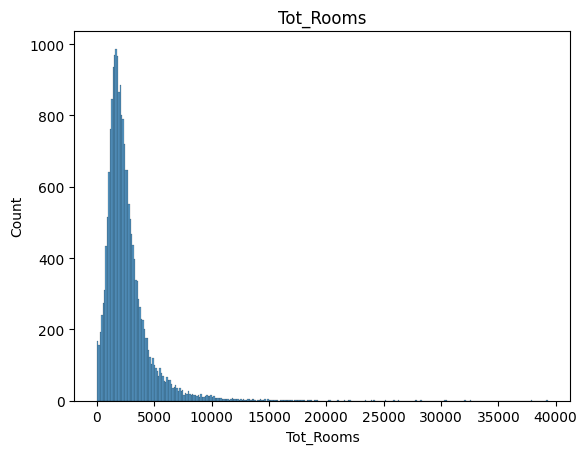

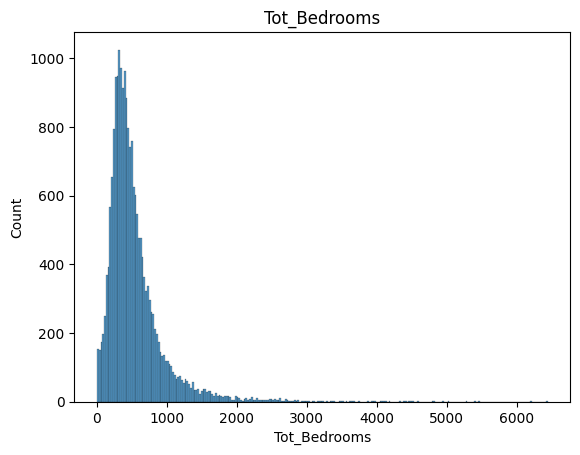

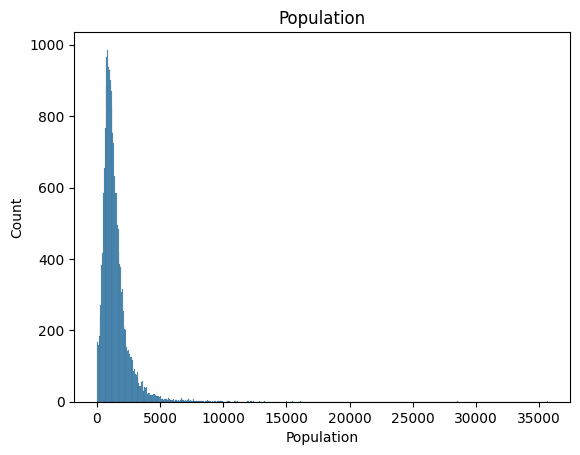

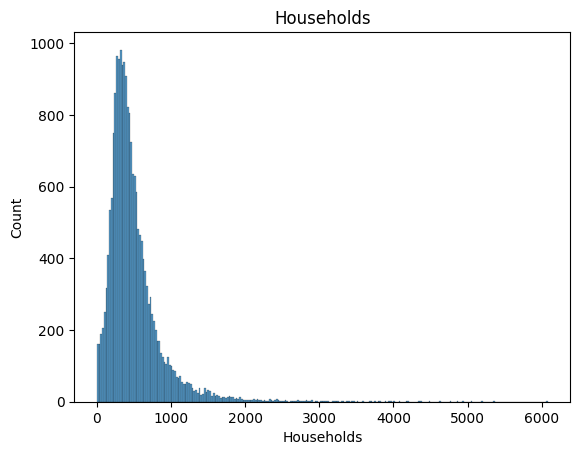

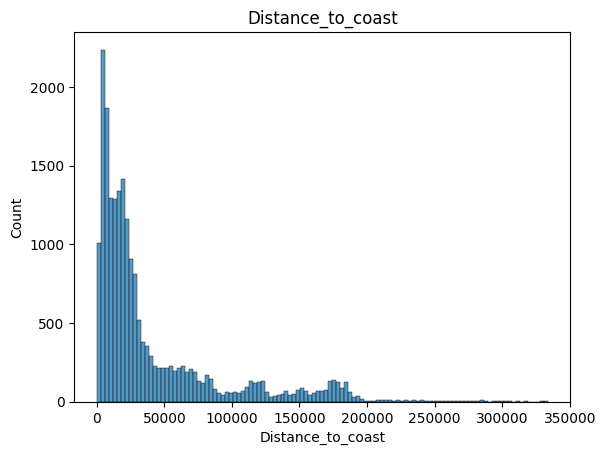

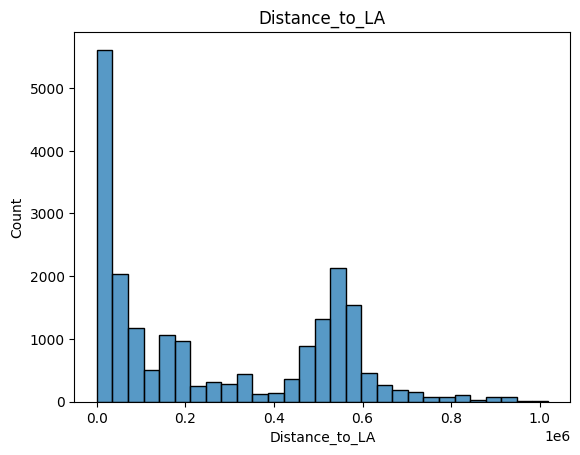

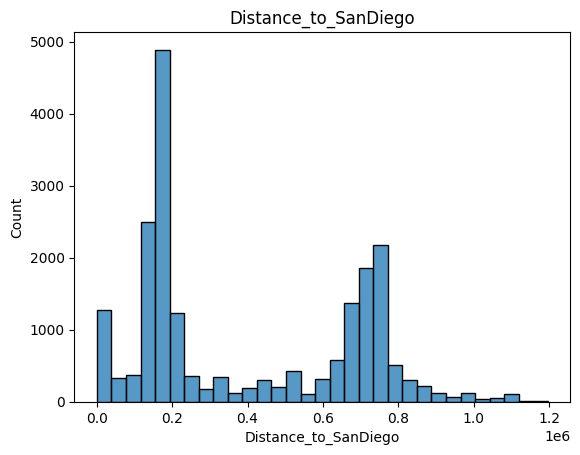

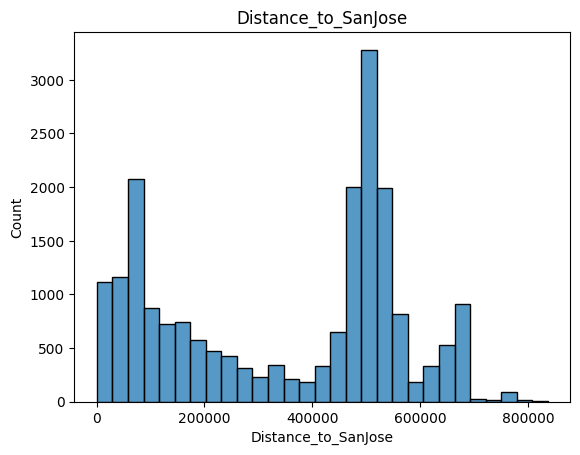

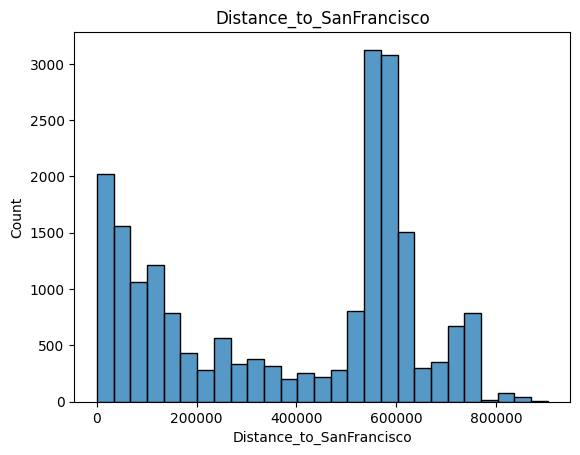

In [ ]:
for i in num_columns:
  sns.histplot(df[i])
  plt.title(i)
  plt.show()

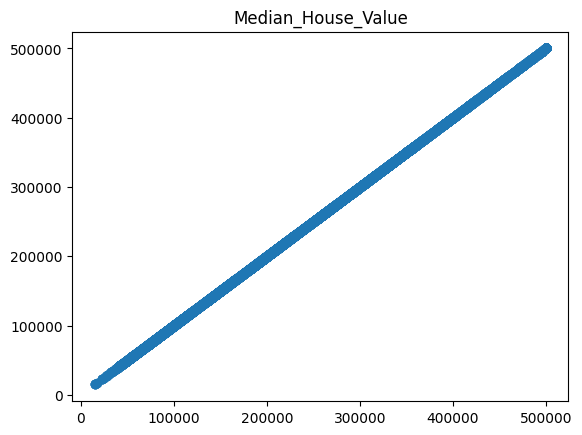

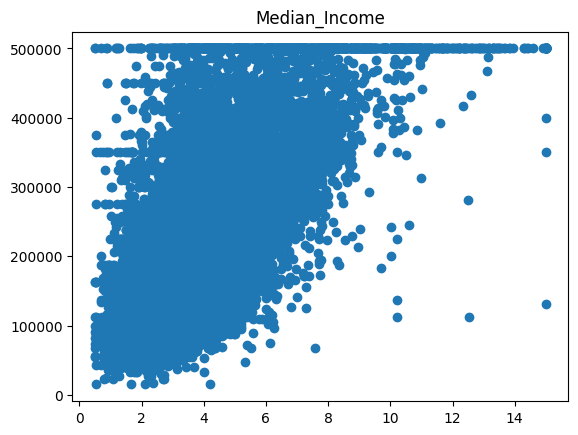

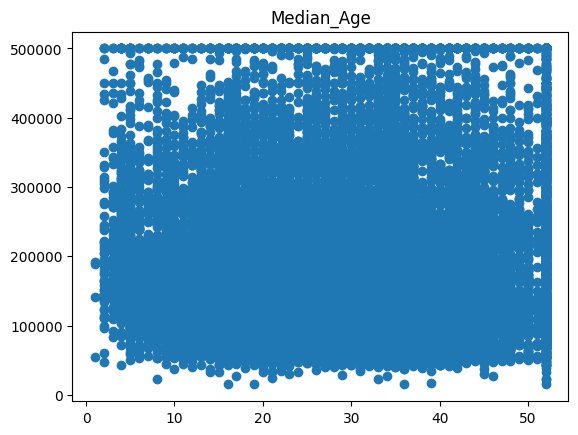

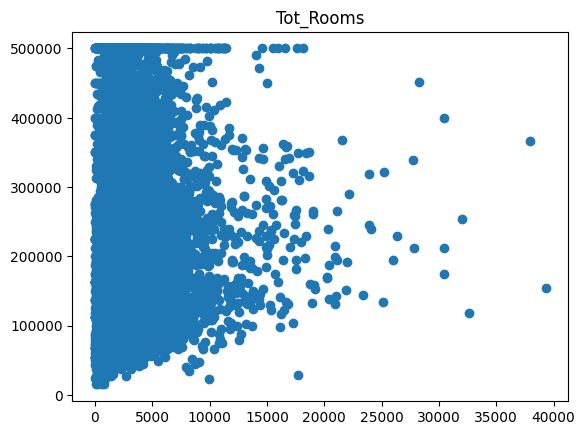

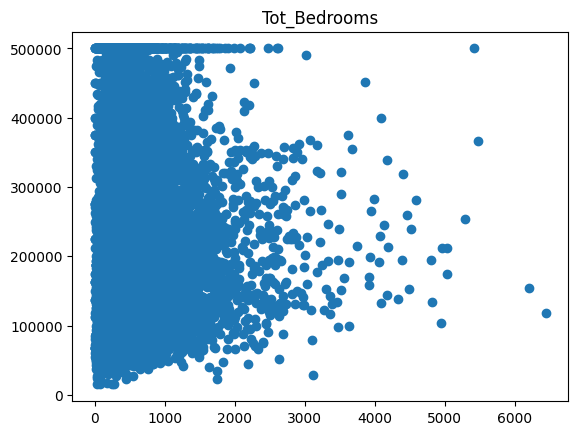

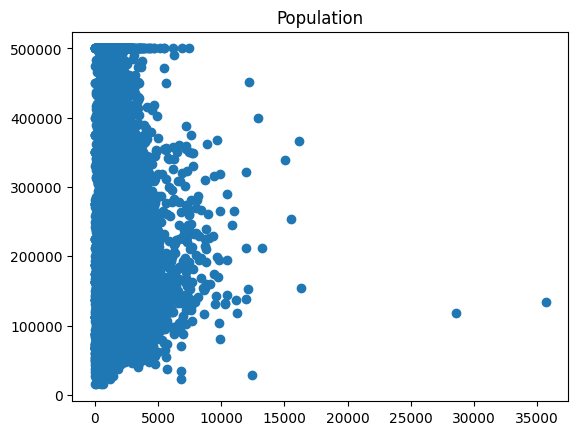

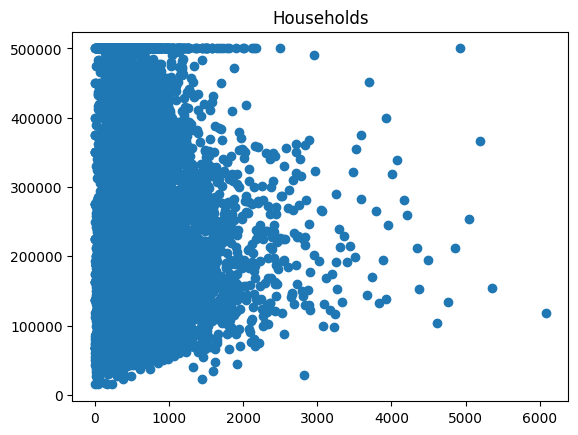

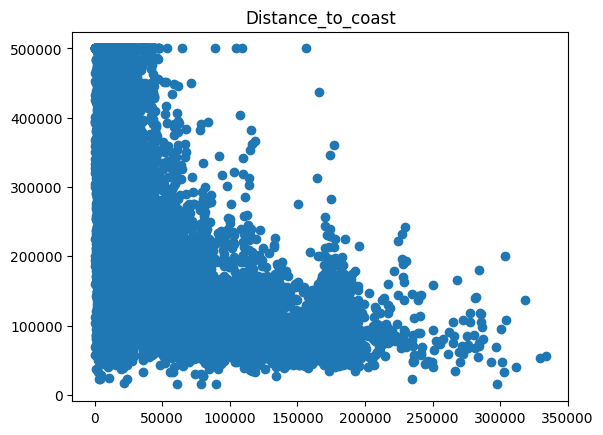

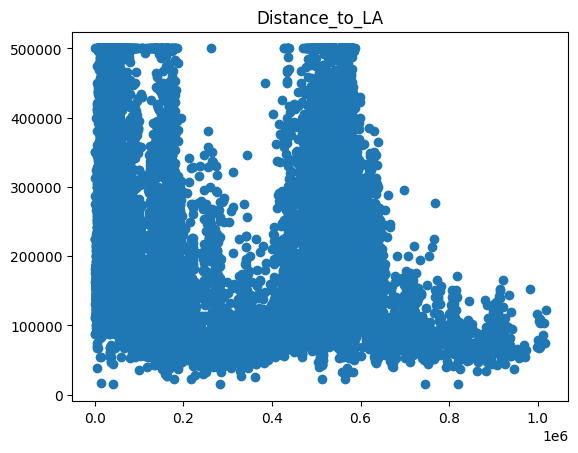

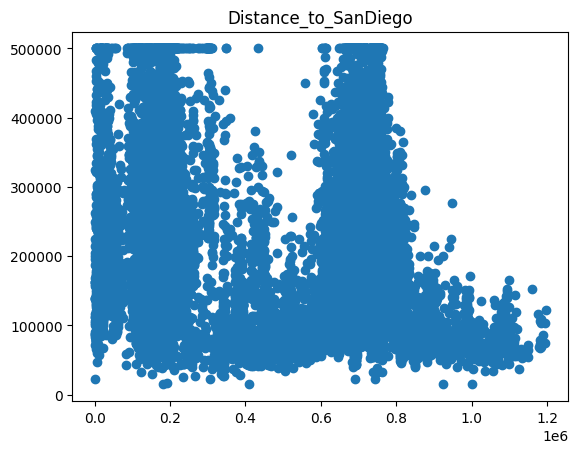

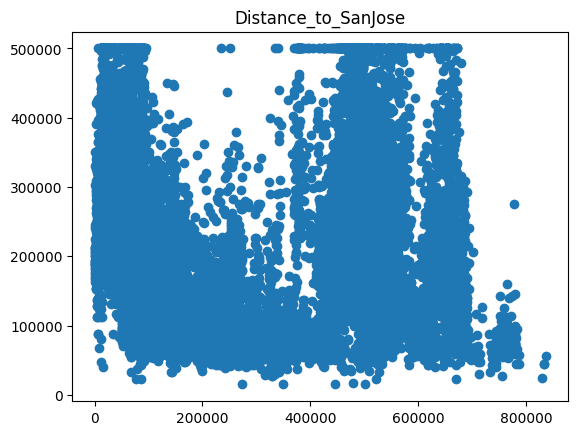

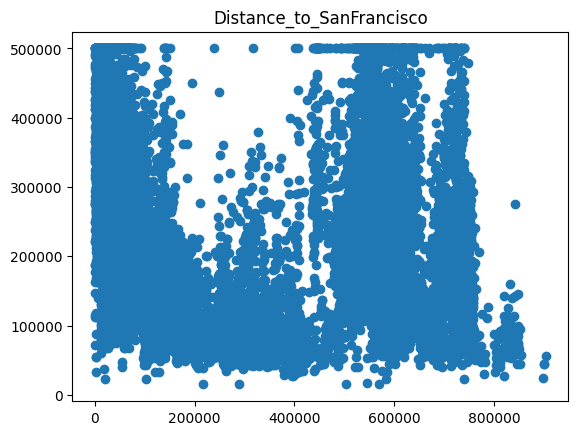

In [ ]:
for i in num_columns:
  plt.scatter(df[i],df['Median_House_Value'])
  plt.title(i)
  plt.show()

<Axes: >

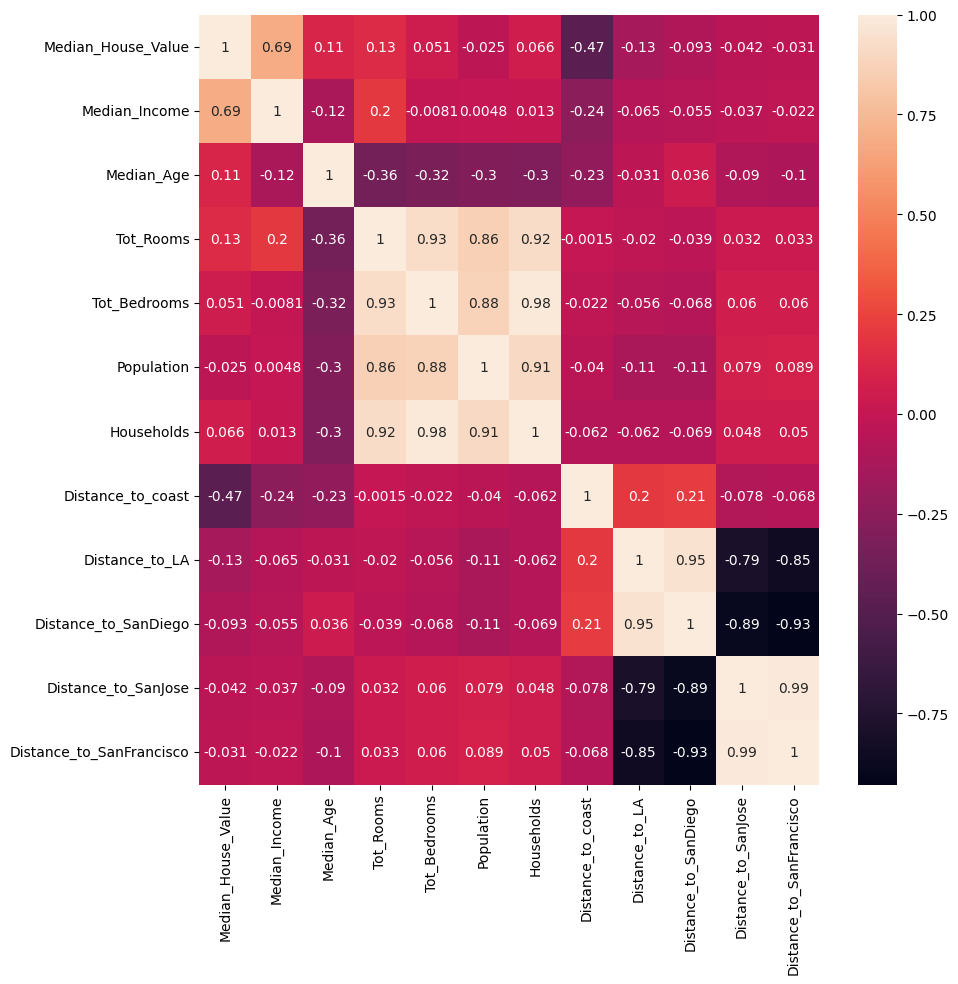

In [ ]:
#heatmap for num columns
plt.figure(figsize=(10,10))
sns.heatmap(df[num_columns].corr(),annot=True)

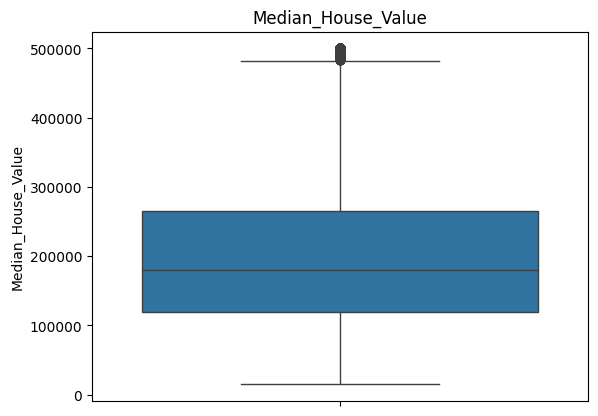

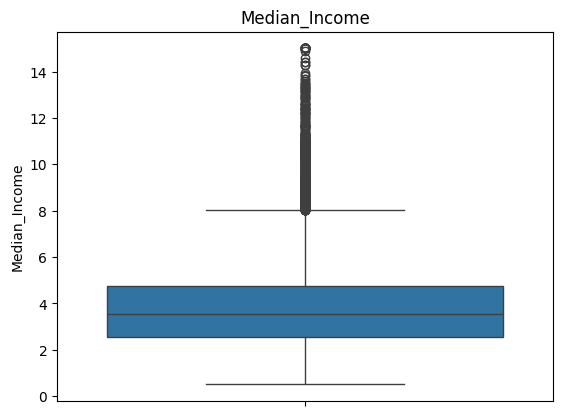

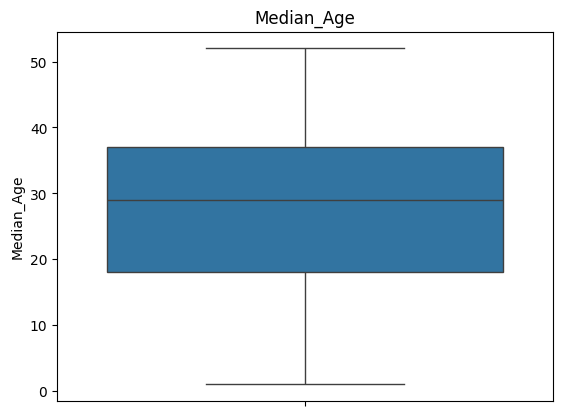

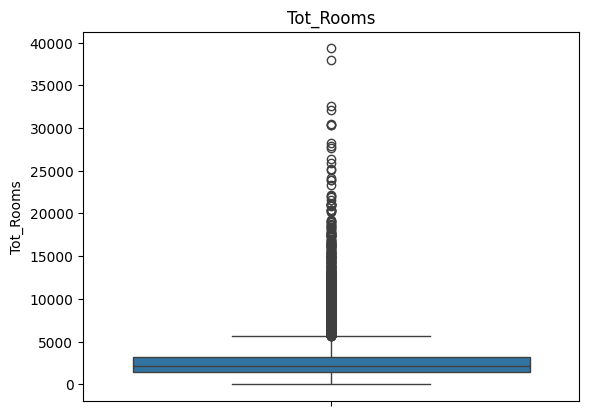

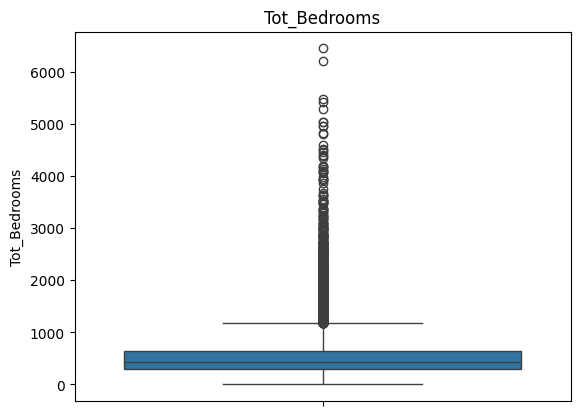

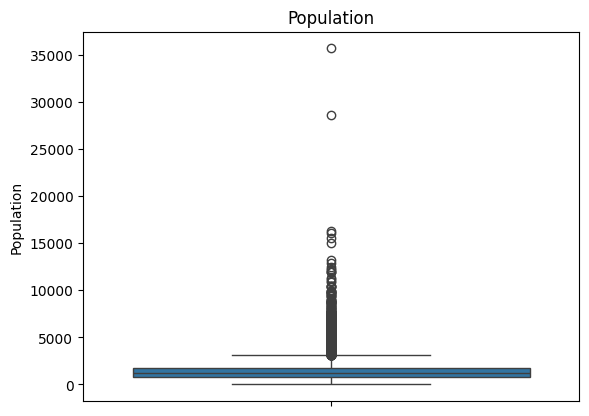

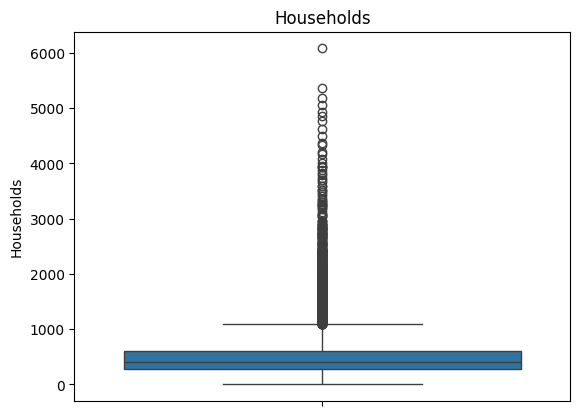

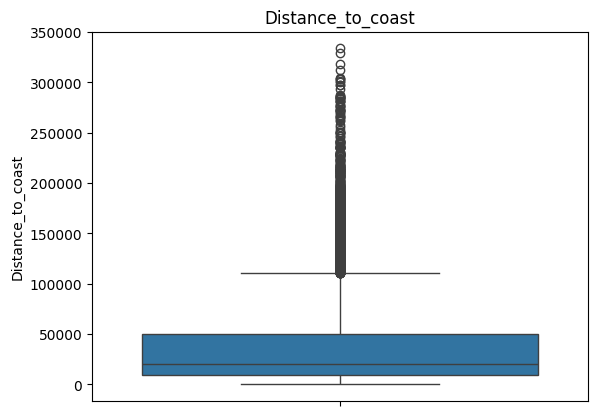

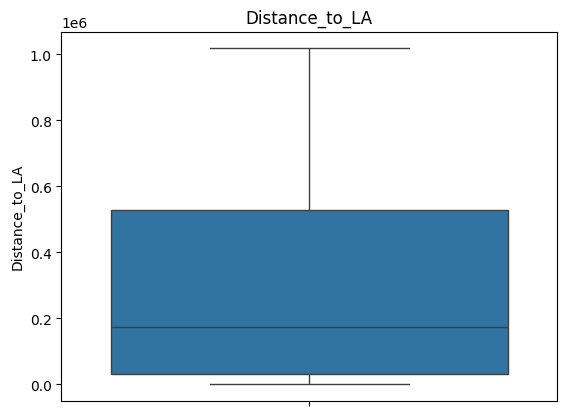

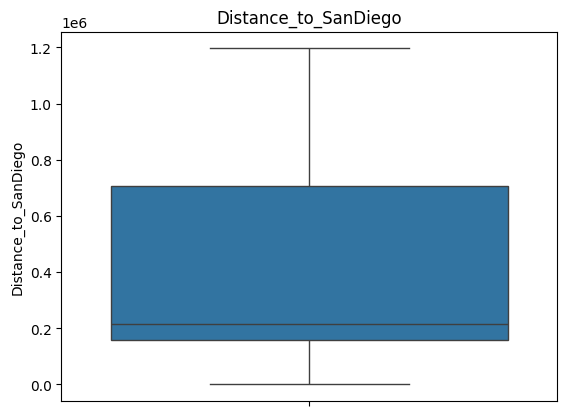

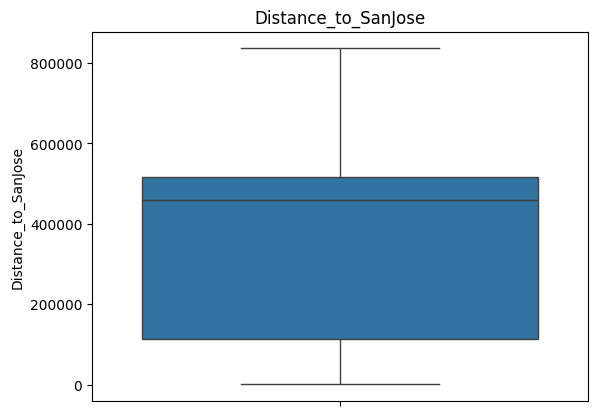

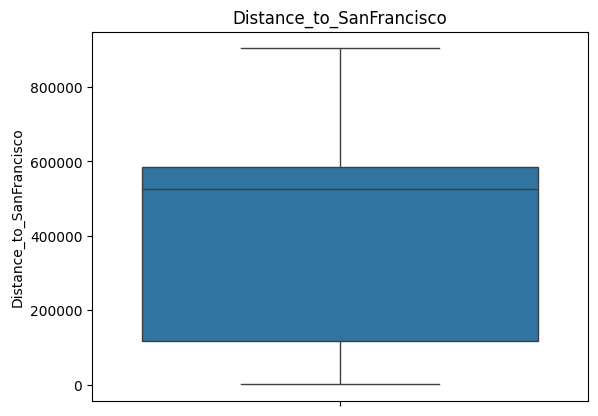

In [ ]:
for i in num_columns:
  sns.boxplot(df[i])
  plt.title(i)
  plt.show()

In [ ]:
# Select numeric columns only
num_columns = df.select_dtypes(include=['int64', 'float64']).columns
# Apply Winsorization (IQR capping)
for col in num_columns:
    Q1 = df[col].quantile(0.25)
    Q3 = df[col].quantile(0.75)
    IQR = Q3 - Q1
    lower = Q1 - 1.5 * IQR
    upper = Q3 + 1.5 * IQR
    df[col] = np.where(df[col] < lower, lower,
                np.where(df[col] > upper, upper, df[col]))
print("New shape after removing outliers:", df.shape)

New shape after removing outliers: (20640, 12)


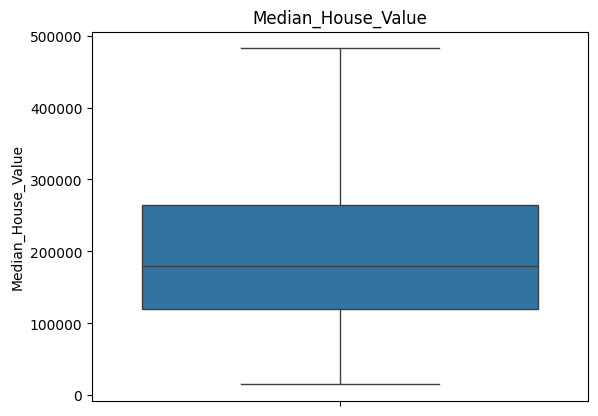

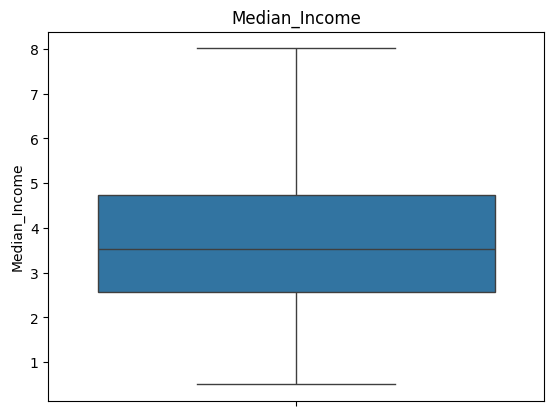

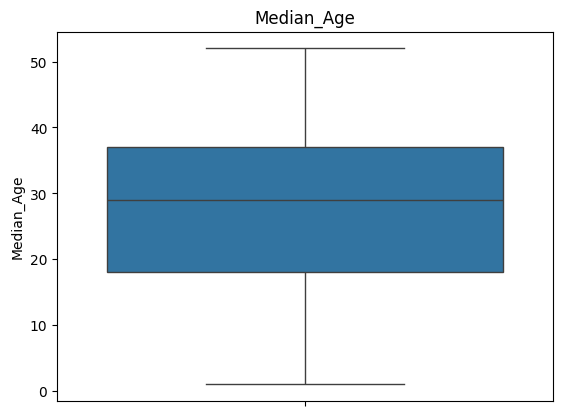

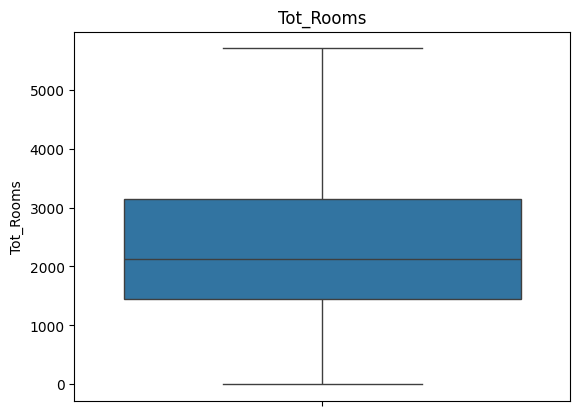

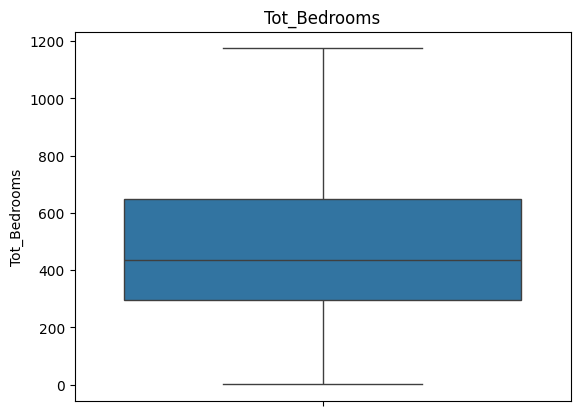

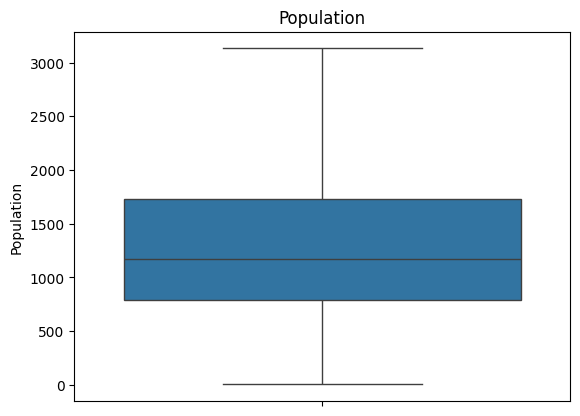

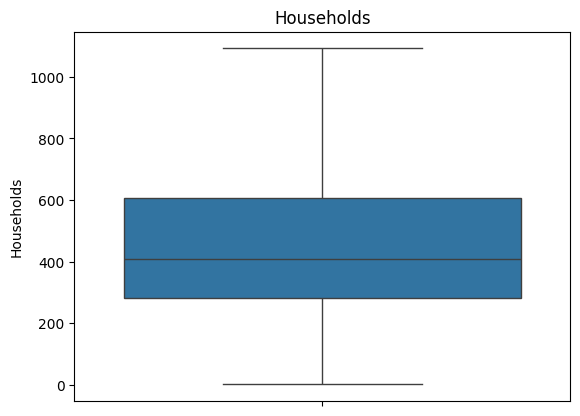

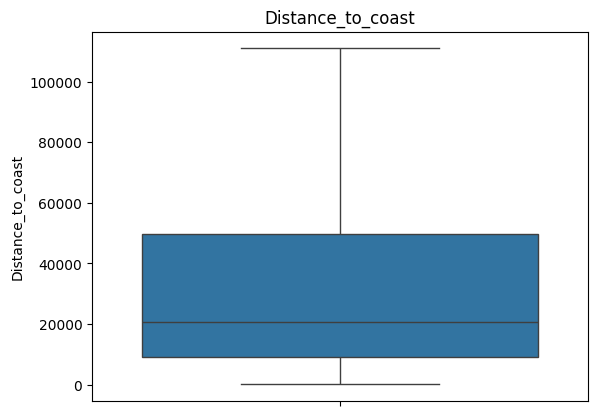

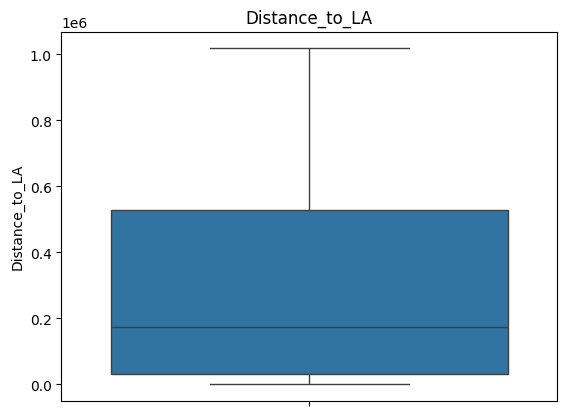

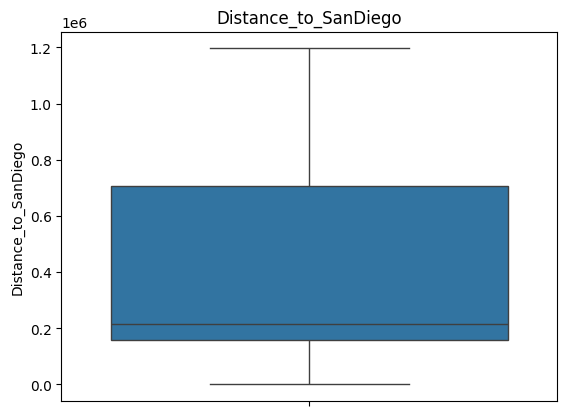

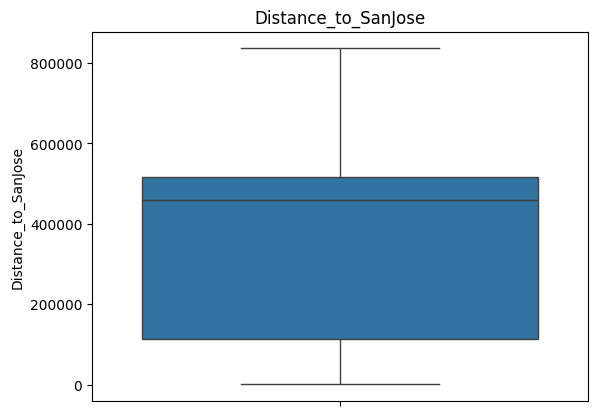

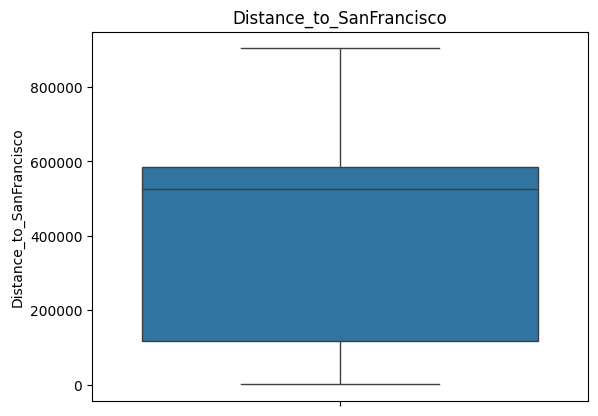

In [ ]:
for i in num_columns:
  sns.boxplot(df[i])
  plt.title(i)
  plt.show()

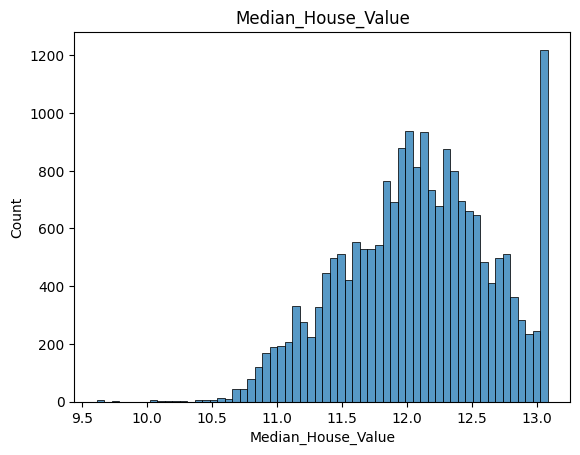

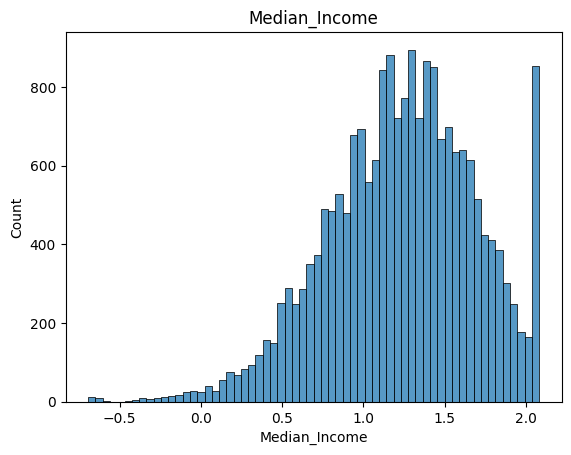

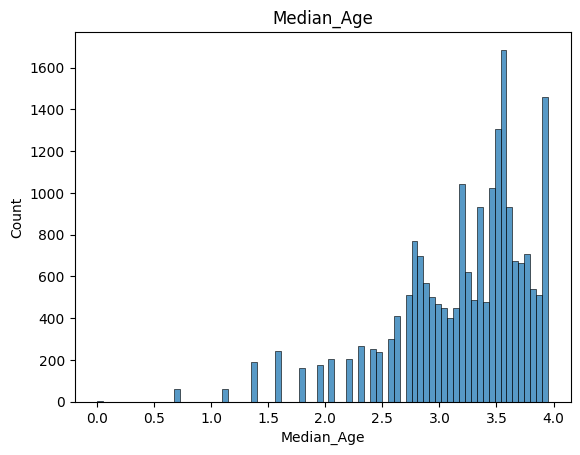

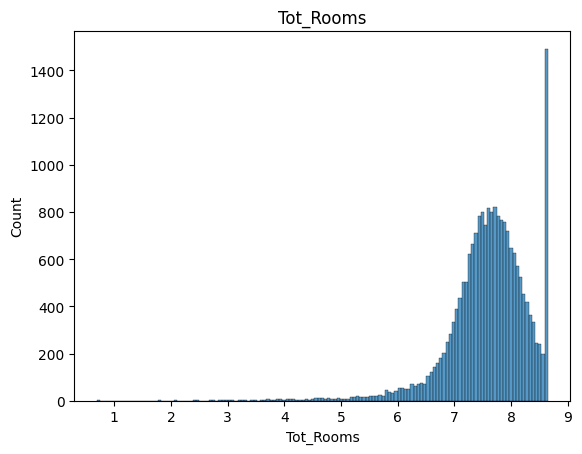

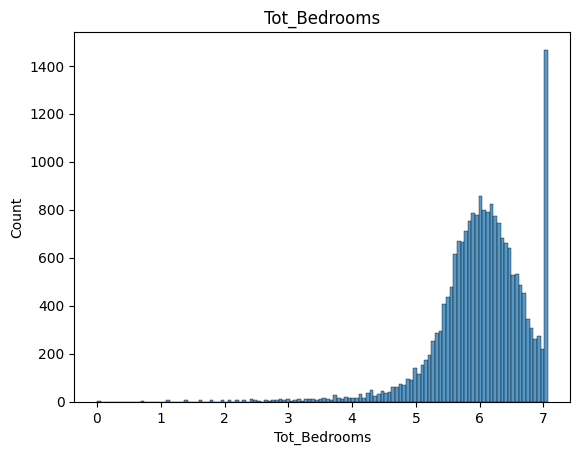

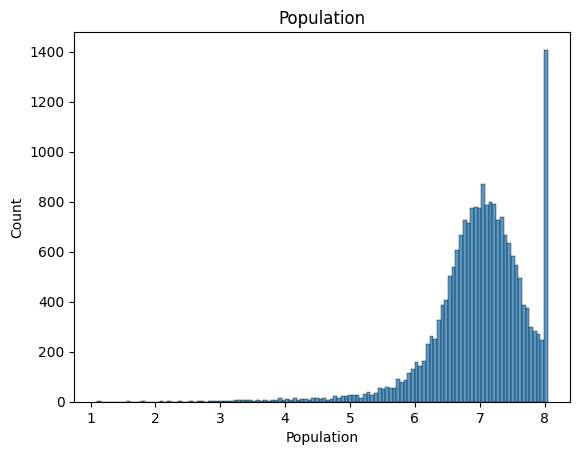

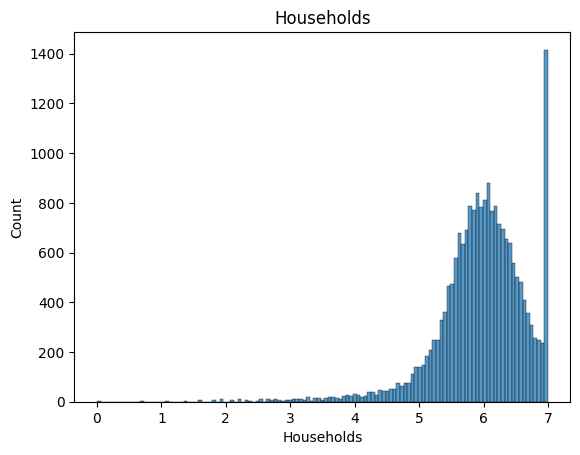

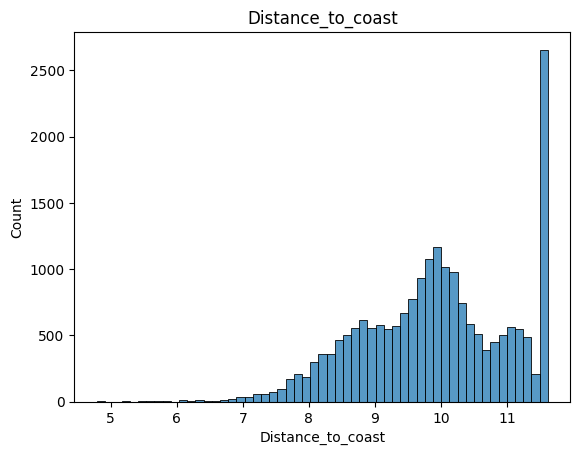

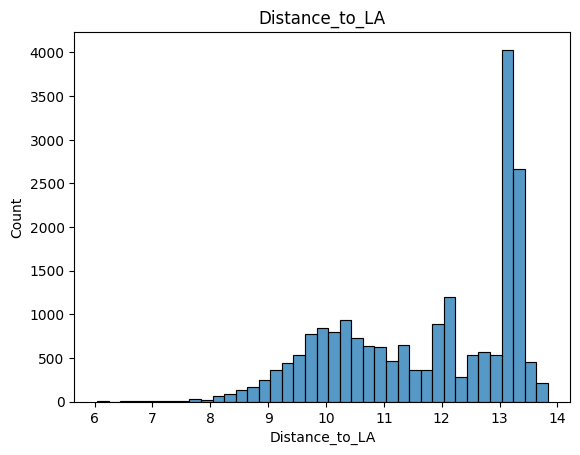

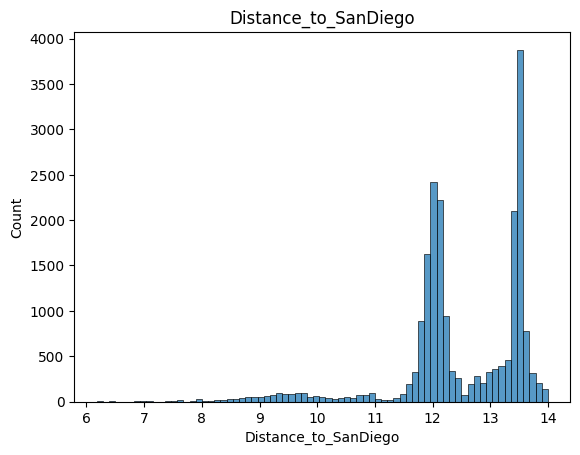

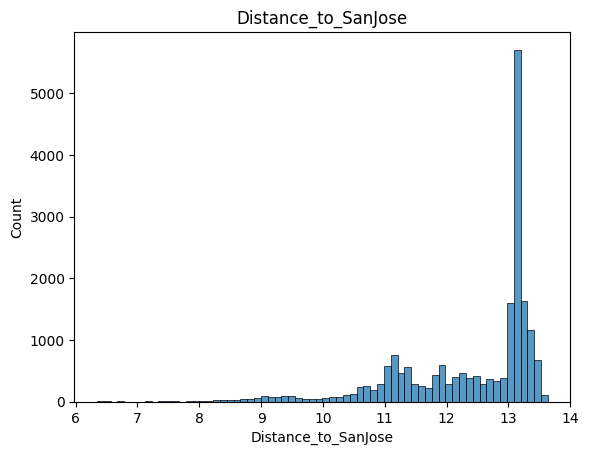

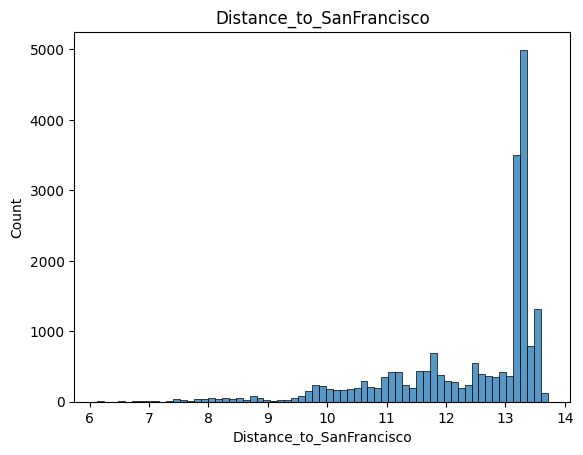

In [ ]:
#histogram for all num columns
for i in num_columns:
  sns.histplot(np.log(df[i]))
  plt.title(i)
  plt.show()

In [ ]:
# standerscaler
numeric_cols = df.select_dtypes(include=['number']).columns
scaler = StandardScaler()
df[numeric_cols] = scaler.fit_transform(df[numeric_cols])

In [ ]:
df

,Median_House_Value,Median_Income,Median_Age,Tot_Rooms,Tot_Bedrooms,Population,Households,Distance_to_coast,Distance_to_LA,Distance_to_SanDiego,Distance_to_SanJose,Distance_to_SanFrancisco
0,2.178330,2.541006,0.982143,-1.117285,-1.299864,-1.325821,-1.291972,-0.735065,1.158969,1.165668,-1.297546,-1.461074
1,1.347165,2.541006,-0.607019,2.329936,2.098242,1.389936,2.348314,-0.707676,1.149889,1.157842,-1.308518,-1.462552
2,1.290635,2.085156,1.856182,-0.697327,-1.087700,-1.098528,-1.099883,-0.763629,1.151224,1.158840,-1.309359,-1.470824
3,1.195241,1.111288,1.856182,-0.835405,-0.931185,-1.017539,-0.941691,-0.777598,1.153580,1.160808,-1.307426,-1.473945
4,1.203191,0.027262,1.856182,-0.582857,-0.774670,-1.008395,-0.791033,-0.777598,1.153580,1.160808,-1.307426,-1.473945
...,...,...,...,...,...,...,...,...,...,...,...,...
20635,-1.129547,-1.351765,-0.289187,-0.555671,-0.447729,-0.642637,-0.523614,2.158203,1.554570,1.494389,-0.463643,-0.655969
20636,-1.138380,-0.750601,-0.845393,-1.248209,-1.226824,-1.281408,-1.337170,2.158203,1.575629,1.513790,-0.471288,-0.673183
20637,-1.004122,-1.267488,-0.924851,-0.134281,-0.061659,-0.431019,-0.135668,2.158203,1.552601,1.494624,-0.502040,-0.698038
20638,-1.071251,-1.166620,-0.845393,-0.416162,-0.325995,-0.778490,-0.452051,2.158203,1.567358,1.508353,-0.511151,-0.714729


In [ ]:
#spliting data to features matrix and label vector
features=df.drop(columns="Median_House_Value")
label=df["Median_House_Value"]

In [ ]:
normalized_features=(features-features.min())/(features.max()-features.min())
normalized_features.head()

,Median_Income,Median_Age,Tot_Rooms,Tot_Bedrooms,Population,Households,Distance_to_coast,Distance_to_LA,Distance_to_SanDiego,Distance_to_SanJose,Distance_to_SanFrancisco
0,1.000000,0.784314,0.154133,0.109029,0.101950,0.114521,0.082486,0.546362,0.614340,0.079961,0.023023
1,1.000000,0.392157,1.000000,0.941227,0.766379,1.000000,0.091171,0.544152,0.612446,0.077112,0.022614
2,0.899426,1.000000,0.257181,0.160988,0.157558,0.161246,0.073428,0.544477,0.612688,0.076894,0.020323
3,0.684562,1.000000,0.223300,0.199319,0.177373,0.199725,0.068998,0.545050,0.613164,0.077396,0.019459
4,0.445394,1.000000,0.285269,0.237649,0.179610,0.236372,0.068998,0.545050,0.613164,0.077396,0.019459


In [ ]:
# Data Splitting
#split the data into traning set (70%) and a temporary combined validation/test set(30%)
X_train,X_val_test,y_train,y_val_test = train_test_split(normalized_features,label, test_size=0.3, random_state=50)
#split the temporary validation/test set into validation (15%) and test (15%)
X_val,X_test,y_val,y_test = train_test_split(X_val_test,y_val_test, test_size=0.5, random_state=50)

In [ ]:
# Linear Regression
#fitting model
linear_model = LinearRegression().fit(X_train, y_train)
# Printing the coefficients (w matrix)
print("Linear Regression Coefficients:", linear_model.coef_)
# Print the intercept of the linear regression model
print("Linear Regression Intercept:", linear_model.intercept_)

Linear Regression Coefficients: [ 3.03020288  0.41735159 -0.68378101  1.94890883 -1.94868972  0.81212621
 -0.87491681 -1.46372052  0.93216157 -0.16980084 -0.17872799]
Linear Regression Intercept: -1.1151994167629755


In [ ]:
train_acc = linear_model.score(X_train, y_train)
test_acc = linear_model.score(X_test, y_test)
print("Train Score (R²):", train_acc)
print("Test Score (R²):", test_acc)

Train Score (R²): 0.671108256999958
Test Score (R²): 0.6790455318425553
